Imports

### Dependencies

In [35]:
%pip install numpy pandas matplotlib opencv-python scikit-image scikit-learn joblib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Dataset download

The split script needs these files to retrieve the selected categories

In [36]:
import kagglehub

path = kagglehub.dataset_download("dansbecker/food-101")

print(path)

/Users/brandonpavao/.cache/kagglehub/datasets/dansbecker/food-101/versions/1


### Dataset location

Locate the folder containing the images and official split metadata. Update the dataset path for this notebook session without changing the shared split script

In [37]:
from pathlib import Path
import data_split

for file in Path(path).rglob("train.txt"):
    if file.parent.name == "meta":
        root = file.parent.parent
        if (root / "images").is_dir():
            data_split.DATA_DIR = str(root)
            break
else:
    raise FileNotFoundError("Dataset structure not found")

print("Dataset directory:", data_split.DATA_DIR)

Dataset directory: /Users/brandonpavao/.cache/kagglehub/datasets/dansbecker/food-101/versions/1/food-101/food-101


### Create training and testing DataFrames

Use the existing split function into DataFrames

In [38]:
import pandas as pd
from data_split import load_split

df_train = pd.DataFrame(
    load_split("train"),
    columns=["image_path", "label"]
)

df_test = pd.DataFrame(
    load_split("test"),
    columns=["image_path", "label"]
)

### Inspect dataset size

In [39]:
print(df_train.shape)
print(df_test.shape)

display(df_train.head())
display(df_test.head())

(15000, 2)
(5000, 2)


,image_path,label
0,/Users/brandonpavao/.cache/kagglehub/datasets/...,18
1,/Users/brandonpavao/.cache/kagglehub/datasets/...,18
2,/Users/brandonpavao/.cache/kagglehub/datasets/...,18
3,/Users/brandonpavao/.cache/kagglehub/datasets/...,18
4,/Users/brandonpavao/.cache/kagglehub/datasets/...,18


,image_path,label
0,/Users/brandonpavao/.cache/kagglehub/datasets/...,18
1,/Users/brandonpavao/.cache/kagglehub/datasets/...,18
2,/Users/brandonpavao/.cache/kagglehub/datasets/...,18
3,/Users/brandonpavao/.cache/kagglehub/datasets/...,18
4,/Users/brandonpavao/.cache/kagglehub/datasets/...,18


The training split contains 15,000 rows and the testing split contains 5,000 rows, each with two columns. The first rows share label 18 because the metadata is grouped by category

### Data types and completeness

Inspect column types and non-null counts before working with the images

In [40]:
print("Training dataset")
df_train.info()

print("\nTesting dataset")
df_test.info()

Training dataset
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   image_path  15000 non-null  str  
 1   label       15000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 234.5 KB

Testing dataset
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   image_path  5000 non-null   str  
 1   label       5000 non-null   int64
dtypes: int64(1), str(1)
memory usage: 78.3 KB


Both columns are complete in both splits. Image paths are strings and labels are integers, which are suitable for loading images and identifying classes

### Column exploration

Check the available columns, unique paths and number of classes. The numeric label is a category identifier, not a continuous measurement

In [41]:
print("Columns:", df_train.columns.tolist())

display(df_train.describe(include="all"))

print("Unique training labels:", df_train["label"].nunique())
print("Unique testing labels:", df_test["label"].nunique())

Columns: ['image_path', 'label']


,image_path,label
count,15000,15000.000000
unique,15000,NaN
top,/Users/brandonpavao/.cache/kagglehub/datasets/...,NaN
freq,1,NaN
mean,NaN,9.500000
std,NaN,5.766474
min,NaN,0.000000
25%,NaN,4.750000
50%,NaN,9.500000
75%,NaN,14.250000


Unique training labels: 20
Unique testing labels: 20


The training split has 15,000 unique paths. Both splits contain 20 unique labels, and the training labels range from 0 to 19. Mean label of 9.5 is not a meaningful measure of food characteristics

### Category mapping

Map integer labels to readable food names for easier interpretation during EDA

In [42]:
from data_split import CATEGORIES

category_map = dict(enumerate(CATEGORIES))

df_train["category"] = df_train["label"].map(category_map)
df_test["category"] = df_test["label"].map(category_map)

display(df_train.sample(10, random_state=42))

,image_path,label,category
11499,/Users/brandonpavao/.cache/kagglehub/datasets/...,14,ramen
6475,/Users/brandonpavao/.cache/kagglehub/datasets/...,1,hot_dog
13167,/Users/brandonpavao/.cache/kagglehub/datasets/...,17,steak
862,/Users/brandonpavao/.cache/kagglehub/datasets/...,4,chicken_wings
5970,/Users/brandonpavao/.cache/kagglehub/datasets/...,0,hamburger
6706,/Users/brandonpavao/.cache/kagglehub/datasets/...,1,hot_dog
3017,/Users/brandonpavao/.cache/kagglehub/datasets/...,5,french_fries
3781,/Users/brandonpavao/.cache/kagglehub/datasets/...,16,fried_rice
3898,/Users/brandonpavao/.cache/kagglehub/datasets/...,16,fried_rice
2250,/Users/brandonpavao/.cache/kagglehub/datasets/...,12,donuts


### Missing values

In [43]:
print("Training missing values:")
display(df_train.isnull().sum())

print("Testing missing values:")
display(df_test.isnull().sum())

Training missing values:


image_path    0
label         0
category      0
dtype: int64

Testing missing values:


image_path    0
label         0
category      0
dtype: int64

All three columns contain zero missing values in both splits. No row removal is needed for missing metadata

### Duplicate paths

Counting the same path twice may mess up training a model later on

In [44]:
print("Training duplicates:",
      df_train["image_path"].duplicated().sum())

print("Testing duplicates:",
      df_test["image_path"].duplicated().sum())

Training duplicates: 0
Testing duplicates: 0


**Evaluation:** Both splits contain zero duplicate image paths. This does not rule out visually identical photographs stored under different filenames.

### Split overlap

**Why:** Check whether the same image path appears in both splits to identify direct train/test overlap.

In [45]:
overlap = set(df_train["image_path"]) & set(df_test["image_path"])

print("Overlapping images:", len(overlap))

Overlapping images: 0


Zero shared image paths between training and testing. This rules out direct path overlap, but not every possible form of data leakage.

### Image file availability

To verify each referenced file exists before attempting to decode it.

In [46]:
from pathlib import Path

missing_train = df_train[
    ~df_train["image_path"].map(lambda p: Path(p).is_file())
]

missing_test = df_test[
    ~df_test["image_path"].map(lambda p: Path(p).is_file())
]

print("Missing training images:", len(missing_train))
print("Missing testing images:", len(missing_test))

Missing training images: 0
Missing testing images: 0


### Visual exploration

Display one randomly selected training photograph per category to inspect the appearance of the selected foods.

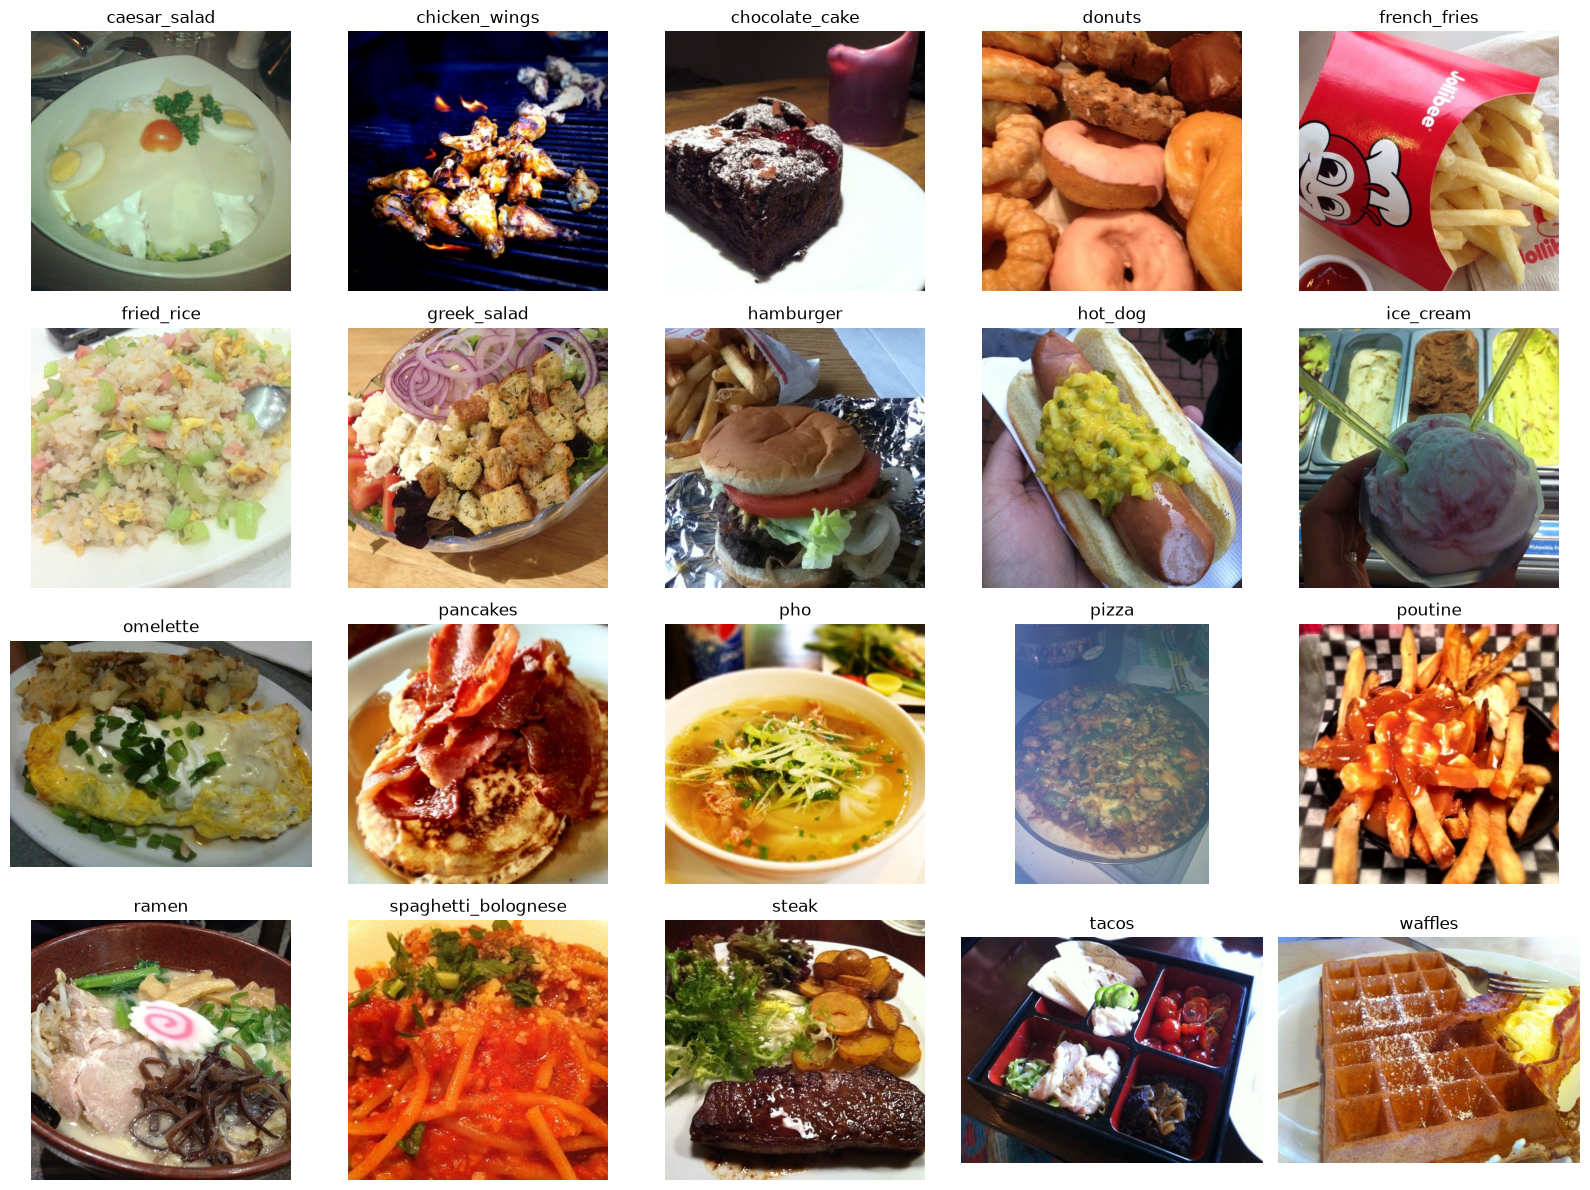

In [47]:
import cv2
import numpy as np

samples = df_train.groupby("category").sample(
    n=1,
    random_state=42
)

fig, axes = plt.subplots(4, 5, figsize=(16, 12))

for ax, (_, row) in zip(axes.flatten(), samples.iterrows()):
    image = cv2.imread(row["image_path"])

    if image is not None:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        ax.imshow(image)

    ax.set_title(row["category"])
    ax.axis("off")

plt.tight_layout()
plt.show()

Provides a visual overview of the training data and motivates exploring colour, shape and texture, not yet establishing which descriptor will classify foods best

### Image dimensions

Inspect 500 randomly selected training images to determine whether a fixed image resolution is needed.

In [48]:
dimensions = []

for path in df_train["image_path"].sample(
    500, random_state=42
):
    image = cv2.imread(path)

    if image is not None:
        height, width = image.shape[:2]

        dimensions.append({
            "width": width,
            "height": height,
            "channels": image.shape[2]
        })

df_dimensions = pd.DataFrame(dimensions)

display(df_dimensions.describe())

,width,height,channels
count,500.000000,500.000000,500.0
mean,495.256000,473.302000,3.0
std,44.628891,66.866232,0.0
min,288.000000,247.000000,3.0
25%,512.000000,384.000000,3.0
50%,512.000000,512.000000,3.0
75%,512.000000,512.000000,3.0
max,512.000000,512.000000,3.0


All 500 sampled images loaded with three channels. Widths range from 288 to 512 pixels and heights from 247 to 512 pixels. Mean width is 495.26 and mean height is 473.30 pixels. The variation supports resizing to a common shape

### Dimension distribution

Plot width and height distributions to visualize how image sizes vary.

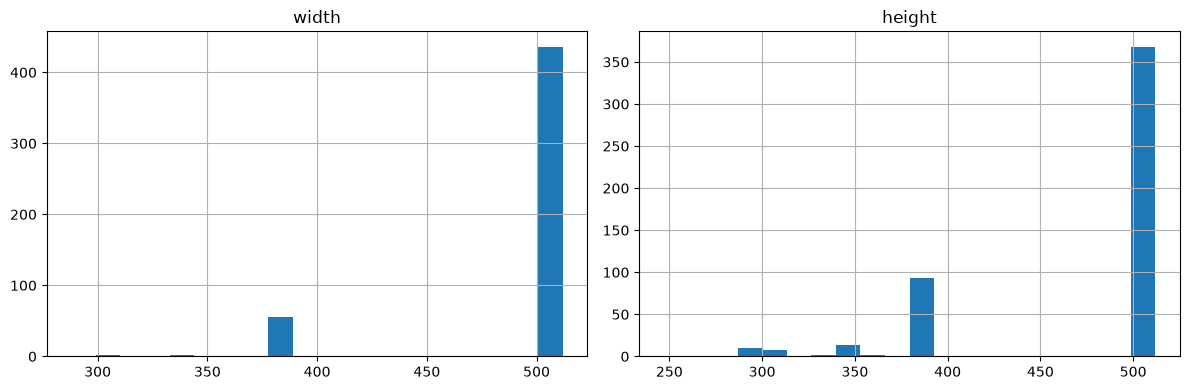

In [49]:
df_dimensions[["width", "height"]].hist(
    bins=20,
    figsize=(12, 4)
)

plt.tight_layout()
plt.show()

Shows that 512 pixels is the median for both axes, with more variation in height (standard deviation 66.87) than width (44.63). A common input size avoids inconsistent feature lengths

### Pixel intensity distribution

Inspect one original image to understand its pixel range, colour representation and data type before normalization

Image shape: (512, 512, 3)
Data type: uint8
Minimum pixel: 0
Maximum pixel: 255


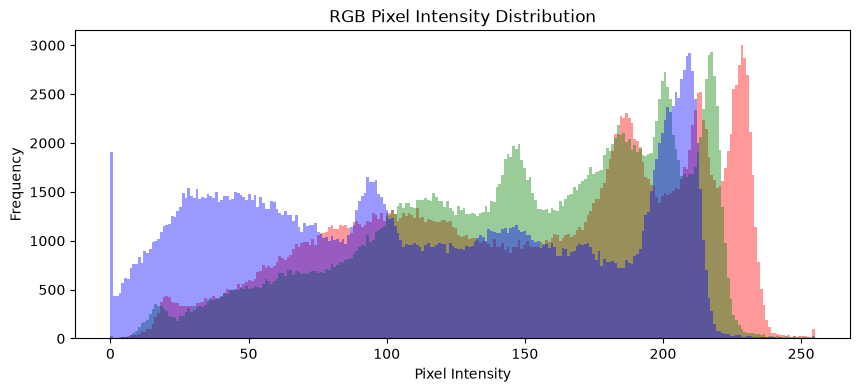

In [50]:
image = cv2.imread(df_train.iloc[0]["image_path"])
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image shape:", image.shape)
print("Data type:", image.dtype)
print("Minimum pixel:", image.min())
print("Maximum pixel:", image.max())

plt.figure(figsize=(10, 4))

for i, color in enumerate(["red", "green", "blue"]):
    plt.hist(
        image[:, :, i].ravel(),
        bins=256,
        color=color,
        alpha=0.4
    )

plt.title("RGB Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

The sampled image has shape `(512, 512, 3)`, type `uint8`, and pixel values from 0 to 255. Dividing by 255 converts this representation to the intended normalized range.

### Preprocessing function

Convert OpenCV's BGR output to RGB, resize to 128 × 128, and scale pixels to [0, 1]. This gives each image a consistent shape and numeric range

In [51]:
IMAGE_SIZE = (128, 128)

def preprocess_image(path):
    image = cv2.imread(path)

    if image is None:
        return None

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, IMAGE_SIZE)
    image = image.astype(np.float32) / 255.0

    return image

Direct square resizing may distort non-square images, and smaller images may lose fine detail. Its output can be tested later

### Preprocessing validation

Compare the original and processed sample to check the effect of resizing and normalization

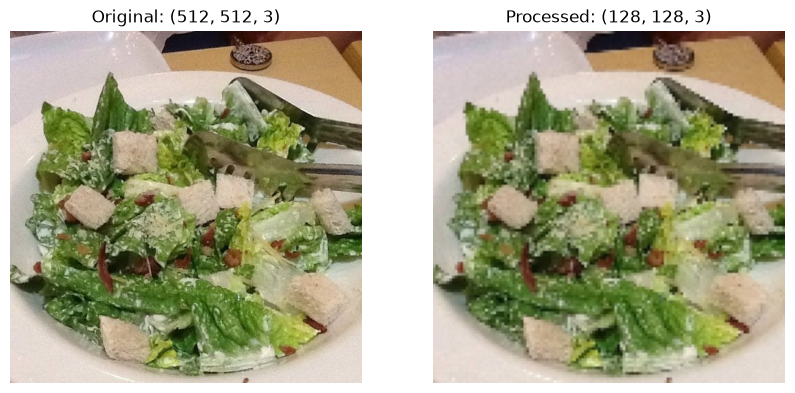

Minimum pixel: 0.0
Maximum pixel: 1.0


In [52]:
path = df_train.iloc[0]["image_path"]

original = cv2.cvtColor(
    cv2.imread(path),
    cv2.COLOR_BGR2RGB
)

processed = preprocess_image(path)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original)
axes[0].set_title(f"Original: {original.shape}")

axes[1].imshow(processed)
axes[1].set_title(f"Processed: {processed.shape}")

for ax in axes:
    ax.axis("off")

plt.show()

print("Minimum pixel:", processed.min())
print("Maximum pixel:", processed.max())

The saved output confirms a minimum of 0.0 and maximum of 1.0 after preprocessing. Resizing a 512 × 512 sample to 128 × 128 reduces its spatial pixel count by 93.75%. This verifies the sample, not yet the full dataset

# Color Histogram Extraction

Use 16 bins per RGB channel to describe overall colour distribution without retaining every pixel. Normalize each histogram to represent relative frequencies

In [53]:
def extract_color(image):
    features = []

    for channel in range(3):
        hist, _ = np.histogram(
            image[:, :, channel],
            bins=16, # produces 48 features
            range=(0, 1)
        )

        hist = hist / hist.sum()
        features.extend(hist)

    return np.array(features)

The design yields 48 features (3 channels × 16 bins). The later sample test confirms this count. Global histograms discard spatial colour arrangement

# HOG extraction

Use HOG to describe local edge directions and shape. Grayscale conversion focuses this descriptor on intensity gradients rather than colour

In [54]:
from skimage.feature import hog
from skimage.color import rgb2gray

def extract_hog(image):
    gray = rgb2gray(image)

    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    return features

At 128 × 128, the configuration forms 7 × 7 overlapping blocks, each with 4 cells and 9 orientations, giving 1,764 features. The sample test confirms this count

# LBP Extraction

Use uniform LBP with eight neighbours and radius one to describe local texture. Convert grayscale values to integers before calculating the patterns

In [55]:
from skimage.feature import local_binary_pattern

def extract_lbp(image):
    gray = rgb2gray(image)
    gray = (gray * 255).astype(np.uint8)

    lbp = local_binary_pattern(
        gray,
        P=8,
        R=1,
        method="uniform"
    )

    hist, _ = np.histogram(
        lbp.ravel(),
        bins=10,
        range=(0, 10)
    )

    return hist / hist.sum()

Uniform LBP produces 10 histogram bins for eight neighbours. The later test confirms the count

# Combine Features

Concatenate colour, shape and texture descriptors into one fixed-length feature vector per image

In [56]:
def extract_features(image):
    color_features = extract_color(image)
    hog_features = extract_hog(image)
    lbp_features = extract_lbp(image)

    return np.concatenate([
        color_features,
        hog_features,
        lbp_features
    ])

 The combined vector is designed to contain 1,822 features. The relative usefulness of each descriptor remains to be measured during model validation

# Test

Test the extraction functions on one image before running the full dataset

In [57]:
image = preprocess_image(
    df_train.iloc[0]["image_path"]
)

print("Colour features:", len(extract_color(image)))
print("HOG features:", len(extract_hog(image)))
print("LBP features:", len(extract_lbp(image)))

features = extract_features(image)

print("Total features:", len(features))
print("Invalid values:", (~np.isfinite(features)).sum())

Colour features: 48
HOG features: 1764
LBP features: 10
Total features: 1822
Invalid values: 0


The sample produced 48 colour, 1,764 HOG and 10 LBP features, totaling 1,822 with zero non-finite values. This is about 96.3% fewer values than the 49,152 resized RGB pixel values.

# Apply preprocessing and feature extraction

Apply the same preprocessing and feature extraction to every image while preserving its label. Record unreadable image paths separately

In [58]:
from tqdm import tqdm

def process_dataset(df):
    X = []
    y = []
    failed = []

    for row in tqdm(
        df.itertuples(),
        total=len(df)
    ):
        image = preprocess_image(row.image_path)

        if image is None:
            failed.append(row.image_path)
            continue

        features = extract_features(image)

        X.append(features)
        y.append(row.label)

    return np.array(X, dtype=np.float32), np.array(y), failed

Keeps feature rows and labels aligned by appending them together. The later validation checks whether any images were skipped or produced invalid features

# process training and test splits

### Training features

Process the training split independently so its features remain separate from the test set

In [59]:
X_train, y_train, failed_train = process_dataset(df_train)

100%|██████████| 15000/15000 [01:11<00:00, 210.48it/s]


The saved progress output reached 15,000 of 15,000 images in approximately 38 seconds on the recorded machine

### Testing features

Apply the identical pipeline to the held-out testing split without fitting any parameters on it

In [60]:
X_test, y_test, failed_test = process_dataset(df_test)

100%|██████████| 5000/5000 [00:24<00:00, 204.85it/s]


The saved progress output reached 5,000 of 5,000 images in approximately 13 seconds

# validate results

Check feature matrix dimensions, label counts, failed images and non-finite values before scaling

In [61]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("Failed training images:", len(failed_train))
print("Failed testing images:", len(failed_test))

print("Invalid training values:",
      (~np.isfinite(X_train)).sum())

print("Invalid testing values:",
      (~np.isfinite(X_test)).sum())

X_train: (15000, 1822)
X_test: (5000, 1822)
y_train: (15000,)
y_test: (5000,)
Failed training images: 0
Failed testing images: 0
Invalid training values: 0
Invalid testing values: 0


Training features have shape `(15000, 1822)` and testing features have shape `(5000, 1822)`. Label arrays contain 15,000 and 5,000 entries. Both splits have zero failed images and zero non-finite feature values

# Standardization

KNN relies on distances between observations. SVM is also sensitive to feature scales. Standardization prevents differences in feature magnitude from unnecessarily dominating the models.

In [62]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Export for models

load these files instead of repeating image preprocessing and feature extraction

In [63]:
import joblib
from pathlib import Path

output = Path("features")
output.mkdir(exist_ok=True)

np.save(output / "X_train.npy", X_train)
np.save(output / "X_test.npy", X_test)

np.save(output / "X_train_scaled.npy", X_train_scaled)
np.save(output / "X_test_scaled.npy", X_test_scaled)

np.save(output / "y_train.npy", y_train)
np.save(output / "y_test.npy", y_test)

joblib.dump(scaler, output / "scaler.pkl")
joblib.dump(category_map, output / "category_map.pkl")

print("All features saved successfully.")

All features saved successfully.
